# RealPDE Track1 - FST-style HMoE Mixer Training

This notebook trains an FST-inspired spatiotemporal HMoE mixer on top of frozen FNO/CNO/Transolver predictions.

- You get tqdm progress bars in-notebook.
- You also get a **live-updating loss plot** every epoch.
- Cached base predictions are reused so hyperparameter sweeps are fast after the first cache build.

In [2]:
import os, sys

import mlflow
mlflow.autolog()

ROOT = r"C:\\Desktop\\RealPDE\\Track1"
if os.getcwd() != ROOT:
    os.chdir(ROOT)

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
EXP = os.path.join(ROOT, "experiments")
if EXP not in sys.path:
    sys.path.insert(0, EXP)

print("cwd:", os.getcwd())

cwd: C:\Desktop\RealPDE\Track1


In [3]:
import torch
from finetune.train_fst_hmoe import TrainConfig, build_cached_datasets, fit_with_cached

print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())

torch: 2.12.0+cu130
cuda available: True


In [4]:
# Main config - tweak this cell between runs
cfg = TrainConfig(
    data_dir=r"C:\\Desktop\\RealPDE\\data\\train_real",
    batch_size=8,
    cache_batch_size=2,
    lr=2e-4,
    weight_decay=1e-4,
    epochs=40,
    early_stopping_patience=8,
    lr_scheduler_patience=4,
    kmse_weight=1.0,
    tke_weight=0.5,
    mse_weight=0.0,
    d_model=48,
    num_layers=2,
    num_heads=4,
    window_size=4,
    n_experts=6,
    n_mlp_experts=3,
    n_tcn_experts=3,
    dropout=0.0,
    device="cuda" if torch.cuda.is_available() else "cpu",
    use_amp=True,
)
cfg

TrainConfig(data_dir='C:\\\\Desktop\\\\RealPDE\\\\data\\\\train_real', fno_ckpt='C:\\Desktop\\RealPDE\\Track1\\checkpoints\\sim_real_ft\\sim_real_fno_fp16.pth', cno_ckpt='C:\\Desktop\\RealPDE\\Track1\\checkpoints\\sim_real_ft\\sim_real_cno.pth', transolver_ckpt='C:\\Desktop\\RealPDE\\Track1\\checkpoints\\sim_real_ft\\sim_real_transolver.pth', save_dir='C:\\Desktop\\RealPDE\\Track1\\checkpoints\\fst_hmoe', checkpoint_name='best_fst_hmoe.pth', val_fraction=0.15, seed=42, d_model=48, num_layers=2, num_heads=4, window_size=4, n_experts=6, n_mlp_experts=3, n_tcn_experts=3, mlp_ratio=2.0, tcn_kernel=3, dropout=0.0, batch_size=8, cache_batch_size=2, lr=0.0002, weight_decay=0.0001, epochs=40, grad_clip=1.0, early_stopping_patience=8, lr_scheduler_patience=4, lr_scheduler_factor=0.5, kmse_weight=1.0, tke_weight=0.5, mse_weight=0.0, kmse_sigma=0.7071067811865476, device='cuda', num_workers=0, cache_dtype='float16', use_amp=True)

In [5]:
# One-time cache build (can take a few minutes)
device = torch.device(cfg.device)
train_cached, val_cached = build_cached_datasets(cfg, device=device)

Loading RealPDE datasets …
  train windows: 2908  val windows: 475
Loading frozen base models (FNO/CNO/Transolver) …
Precomputing frozen base predictions (one-time cost) …


  cached train: torch.Size([2908, 20, 32, 64, 9])   cached val: torch.Size([475, 20, 32, 64, 9])


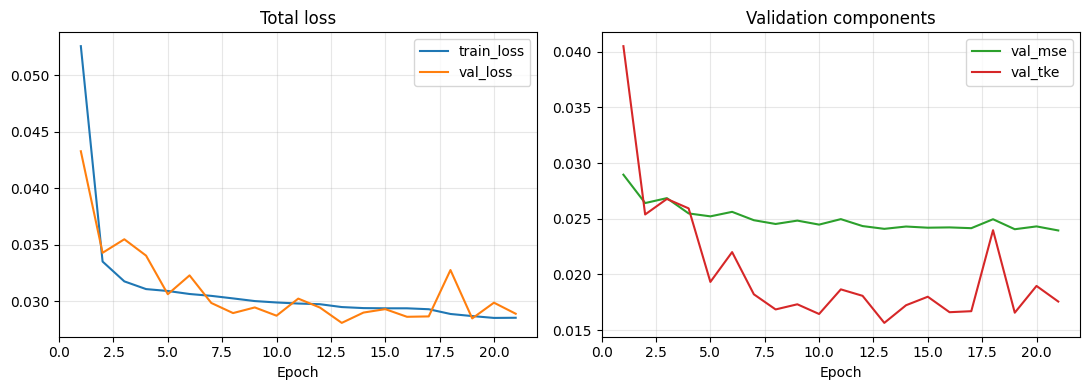

Epochs:  50%|█████     | 20/40 [47:00<47:00, 141.01s/ep, tke=0.01756, tr=0.02856, val=0.02891]


Early stopping: no val improvement for 8 epochs.

Done. Best checkpoint: C:\Desktop\RealPDE\Track1\checkpoints\fst_hmoe\best_fst_hmoe.pth  (val_loss=0.028104)
Live curve image: C:\Desktop\RealPDE\Track1\checkpoints\fst_hmoe\live_curves.png
Best checkpoint: C:\Desktop\RealPDE\Track1\checkpoints\fst_hmoe\best_fst_hmoe.pth


In [6]:
# Train with live-updating curves
history, ckpt_path = fit_with_cached(cfg, train_cached, val_cached, live_plot=True)
print("Best checkpoint:", ckpt_path)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(history["train_loss"]) + 1)
best_ep = int(np.argmin(history["val_loss"])) + 1

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history["train_loss"], label="train_loss")
ax[0].plot(epochs, history["val_loss"], label="val_loss")
ax[0].axvline(best_ep, color="k", linestyle="--", alpha=0.4, label=f"best={best_ep}")
ax[0].set_title("Total loss")
ax[0].set_xlabel("Epoch")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(epochs, history["val_kmse"], label="val_kmse")
ax[1].plot(epochs, history["val_mse"], label="val_mse")
ax[1].plot(epochs, history["val_tke"], label="val_tke")
ax[1].set_title("Validation components")
ax[1].set_xlabel("Epoch")
ax[1].grid(alpha=0.3)
ax[1].legend()

fig.tight_layout()
plt.show()

print(f"Best val_loss = {min(history['val_loss']):.6f} at epoch {best_ep}")

## Fast retune loop (no recache)

After the first cache build, you can tweak `cfg` (LR, tke_weight, d_model, etc.) and rerun only the training cell:

```python
cfg.lr = 1e-4
cfg.tke_weight = 0.5
history, ckpt_path = fit_with_cached(cfg, train_cached, val_cached, live_plot=True)
```